## **Mount Drive**

In [1]:
from google.colab import drive
import os
import time

def mount_drive(retries=3):
    """
    Mount Google Drive with automatic retry handling.

    Args:
        retries (int): Number of mount attempts.

    Returns:
        bool: True if Drive is mounted successfully, otherwise False.
    """
    for attempt in range(retries):
        try:
            # Unmount any existing Drive connection
            try:
                drive.flush_and_unmount()
            except:
                pass

            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)

            # Verify Drive access
            os.listdir('/content/drive/MyDrive')

            print(f"Drive mounted successfully (attempt {attempt + 1})")
            return True

        except Exception as error:
            print(f"Mount attempt {attempt + 1} failed: {error}")
            time.sleep(10)

    print("Drive could not be mounted")
    return False


# Mount Google Drive
mount_drive()

# Project root directory
PROJECT = '/content/drive/MyDrive/fake_image_detection'

print("Environment ready")

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive
Drive mounted successfully (attempt 1)
Environment ready


## **Install Libraries**

In [2]:
# Install external packages
!pip install -q timm grad-cam

# PyTorch
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import (
    Dataset,
    DataLoader,
    Subset,
    WeightedRandomSampler
)

# Model interpretation
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# Data handling
import io
import numpy as np
import pandas as pd
from PIL import Image, ImageChops, ImageEnhance

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
from tqdm import tqdm
import itertools
import os
import random
import shutil
import time

# Configure device
device = torch.device('cuda')

print(f"PyTorch: {torch.__version__} | Device: {device}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 67.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PyTorch: 2.11.0+cu128 | Device: cuda


## **Define paths**

In [3]:
# Define project directories and file paths

# Drive frame directories — source for copying to local storage
FRAMES_REAL = f'{PROJECT}/data/frames/real'
FRAMES_FAKE = f'{PROJECT}/data/frames/fake'

# ELA dataset directories on Drive
ELA_REAL = f'{PROJECT}/data/ela/real'
ELA_FAKE = f'{PROJECT}/data/ela/fake'

# Dataset split and balanced file list directories
SPLIT_DIR    = f'{PROJECT}/data/splits'
BALANCED_DIR = f'{PROJECT}/data/balanced'

# Local directories used during training
# All image data is read from local disk to avoid Drive I/O errors
LOCAL_FRAMES_REAL = '/content/frames/real'
LOCAL_FRAMES_FAKE = '/content/frames/fake'
LOCAL_ELA_REAL    = '/content/ela/real'
LOCAL_ELA_FAKE    = '/content/ela/fake'

# Model, log, and output file paths
CHECKPOINT          = f'{PROJECT}/models/m1_resnet50_checkpoint.pth'
BEST_MODEL          = f'{PROJECT}/models/m1_resnet50_best.pth'
TRAINING_LOG        = f'{PROJECT}/logs/m1_resnet50_log.txt'
SEARCH_RESULTS_FILE = f'{PROJECT}/logs/m1_hyperparameter_search.csv'
PREDICTIONS_DIR     = f'{PROJECT}/predictions'

# Create all local and output directories if they do not exist
for path in [LOCAL_FRAMES_REAL, LOCAL_FRAMES_FAKE,
             LOCAL_ELA_REAL, LOCAL_ELA_FAKE,
             PREDICTIONS_DIR]:
    os.makedirs(path, exist_ok=True)

print("Paths defined successfully")

Paths defined successfully


## **Recompute ELA maps locally**

In [4]:
def compute_ela(img_path, quality=90, scale=15):
    """
    Generate an Error Level Analysis (ELA) map for an image.

    The image is recompressed using JPEG and compared with the
    original image. The pixel differences are amplified to highlight
    potential manipulation artefacts.

    Args:
        img_path (str): Path to the input image.
        quality (int): JPEG compression quality.
        scale (int): Brightness scaling factor.

    """
    try:
        original = Image.open(img_path).convert('RGB')

        buffer = io.BytesIO()
        original.save(buffer, 'JPEG', quality=quality)
        buffer.seek(0)

        recompressed = Image.open(buffer).convert('RGB')

        ela = ImageChops.difference(original, recompressed)

        max_difference = max(
            value[1]
            for value in ela.getextrema()
        ) or 1

        ela = ImageEnhance.Brightness(ela).enhance(
            (255.0 / max_difference) * scale
        )

        return ela

    except Exception:
        return None


def recompute_ela_local(file_list, src_dir, ela_dir, label):
    """
    Generate ELA maps from locally stored images.

    Existing ELA images are skipped, allowing interrupted
    processing to resume safely.

    Args:
        file_list (list): List of image filenames.
        src_dir (str): Source image directory.
        ela_dir (str): Output directory for ELA images.
        label (str): Dataset label.
    """
    os.makedirs(ela_dir, exist_ok=True)

    processed = 0
    skipped = 0
    failed = 0

    for filename in tqdm(file_list, desc=f"ELA {label}"):

        source_path = os.path.join(src_dir, filename)
        image_path = os.path.join(ela_dir, filename)

        ela_filename = (
            filename.replace('.jpg', '_ela.jpg')
                    .replace('.png', '_ela.png')
        )

        ela_path = os.path.join(ela_dir, ela_filename)

        if os.path.exists(ela_path) and os.path.exists(image_path):
            skipped += 1
            continue

        ela_image = compute_ela(source_path)

        if ela_image is not None:
            ela_image.save(ela_path)
            shutil.copy(source_path, image_path)
            processed += 1
        else:
            failed += 1

    print(f"\n{label} ELA")
    print(f"Processed: {processed}")
    print(f"Skipped: {skipped}")
    print(f"Failed: {failed}")
    print(f"Total files: {len(os.listdir(ela_dir))}")


# Load balanced file lists
with open(f'{BALANCED_DIR}/real_files.txt') as file:
    real_balanced = [
        line.strip()
        for line in file
        if line.strip()
    ]

with open(f'{BALANCED_DIR}/fake_files.txt') as file:
    fake_balanced = [
        line.strip()
        for line in file
        if line.strip()
    ]

print(
    f"Balanced dataset: "
    f"{len(real_balanced)} real | "
    f"{len(fake_balanced)} fake"
)


def copy_balanced_files(file_list, src_dir, dst_dir, label):
    """
    Copy the balanced subset of images from Drive to local storage.

    Existing files are skipped, allowing interrupted copies
    to resume safely.

    Args:
        file_list (list): List of filenames to copy.
        src_dir (str): Source directory.
        dst_dir (str): Destination directory.
        label (str): Dataset label.
    """
    os.makedirs(dst_dir, exist_ok=True)

    copied = 0
    skipped = 0
    failed = 0

    for filename in tqdm(file_list, desc=f"Copying {label}"):

        destination = os.path.join(dst_dir, filename)

        if os.path.exists(destination):
            skipped += 1
            continue

        source = os.path.join(src_dir, filename)

        try:
            shutil.copy(source, destination)
            copied += 1

        except Exception:
            failed += 1

    print(
        f"{label}: "
        f"{copied} copied | "
        f"{skipped} skipped | "
        f"{failed} failed"
    )


print("\nCopying balanced frames to local storage")

copy_balanced_files(
    real_balanced,
    FRAMES_REAL,
    LOCAL_FRAMES_REAL,
    "Real frames"
)

copy_balanced_files(
    fake_balanced,
    FRAMES_FAKE,
    LOCAL_FRAMES_FAKE,
    "Fake frames"
)

print("\nComputing ELA maps")

recompute_ela_local(
    real_balanced,
    LOCAL_FRAMES_REAL,
    LOCAL_ELA_REAL,
    "Real"
)

recompute_ela_local(
    fake_balanced,
    LOCAL_FRAMES_FAKE,
    LOCAL_ELA_FAKE,
    "Fake"
)

print("\nLocal ELA status")
print(f"Real: {len(os.listdir(LOCAL_ELA_REAL))}")
print(f"Fake: {len(os.listdir(LOCAL_ELA_FAKE))}")
print("ELA preprocessing complete")

Balanced dataset: 2064 real | 2064 fake

Copying balanced frames to local storage


Copying Real frames: 100%|██████████| 2064/2064 [10:53<00:00,  3.16it/s]


Real frames: 2064 copied | 0 skipped | 0 failed


Copying Fake frames: 100%|██████████| 2064/2064 [17:55<00:00,  1.92it/s]


Fake frames: 2063 copied | 0 skipped | 1 failed

Computing ELA maps


ELA Real: 100%|██████████| 2064/2064 [00:34<00:00, 59.32it/s]



Real ELA
Processed: 2064
Skipped: 0
Failed: 0
Total files: 4128


ELA Fake: 100%|██████████| 2064/2064 [00:22<00:00, 90.12it/s] 


Fake ELA
Processed: 2063
Skipped: 0
Failed: 1
Total files: 4126

Local ELA status
Real: 4128
Fake: 4126
ELA preprocessing complete


## **Dataset class with balanced split loading**

In [9]:
class ELADataset(Dataset):
    """
    Dataset for loading ELA images using pre-balanced file lists.

    The same balanced file lists and split indices are used across
    all project modules to ensure consistent training, validation,
    and testing samples.
    """

    def __init__(
        self,
        real_dir,
        fake_dir,
        real_files,
        fake_files,
        transform=None
    ):
        self.transform = transform
        self.samples = []

        # Add real images
        for filename in real_files:
            path = os.path.join(real_dir, filename)

            if os.path.exists(path):
                self.samples.append((path, 0))

        # Add fake images
        for filename in fake_files:
            path = os.path.join(fake_dir, filename)

            if os.path.exists(path):
                self.samples.append((path, 1))

        real_count = sum(
            1 for _, label in self.samples
            if label == 0
        )

        fake_count = sum(
            1 for _, label in self.samples
            if label == 1
        )

        print(
            f"ELA dataset: {len(self.samples)} samples "
            f"({real_count} real | {fake_count} fake)"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        image = Image.open(image_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label


# Load balanced file lists
with open(f'{BALANCED_DIR}/real_files.txt') as file:
    real_balanced = [
        line.strip()
        for line in file
        if line.strip()
    ]

with open(f'{BALANCED_DIR}/fake_files.txt') as file:
    fake_balanced = [
        line.strip()
        for line in file
        if line.strip()
    ]

# Load predefined dataset splits
train_indices = np.load(
    f'{SPLIT_DIR}/train_indices.npy'
).tolist()

val_indices = np.load(
    f'{SPLIT_DIR}/val_indices.npy'
).tolist()

test_indices = np.load(
    f'{SPLIT_DIR}/test_indices.npy'
).tolist()

# Remove any out-of-range indices caused by the 1 failed fake frame
max_valid = len(real_balanced) + len(fake_balanced) - 1
train_indices = [i for i in train_indices if i <= max_valid]
val_indices   = [i for i in val_indices   if i <= max_valid]
test_indices  = [i for i in test_indices  if i <= max_valid]

print("\nLoaded dataset splits")
print(f"Train: {len(train_indices)}")
print(f"Validation: {len(val_indices)}")
print(f"Test: {len(test_indices)}")

# Data augmentation for training
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Preprocessing for validation and testing
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Create full dataset
full_dataset = ELADataset(
    LOCAL_ELA_REAL,
    LOCAL_ELA_FAKE,
    real_balanced,
    fake_balanced
)

# Remove any out-of-range indices caused by the 1 failed fake frame
max_valid = len(full_dataset.samples) - 1
train_indices = [i for i in train_indices if i <= max_valid]
val_indices   = [i for i in val_indices   if i <= max_valid]
test_indices  = [i for i in test_indices  if i <= max_valid]

# Apply predefined train, validation, and test splits
train_data = Subset(full_dataset, train_indices)
val_data = Subset(full_dataset, val_indices)
test_data = Subset(full_dataset, test_indices)

# Assign transforms
train_data.dataset.transform = train_transform
val_data.dataset.transform = eval_transform
test_data.dataset.transform = eval_transform

# Compute class weights for weighted sampling
labels_list = [
    sample[1]
    for sample in full_dataset.samples
]

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=labels_list
)

weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float
).to(device)

train_labels = [
    full_dataset.samples[index][1]
    for index in train_indices
]

train_sample_weights = [
    class_weights[label]
    for label in train_labels
]

# Create weighted sampler for training
sampler = WeightedRandomSampler(
    weights=train_sample_weights,
    num_samples=len(train_sample_weights),
    replacement=True
)

print("\nDataset ready")
print(f"Train: {len(train_data)}")
print(f"Validation: {len(val_data)}")
print(f"Test: {len(test_data)}")
print(
    f"Class weights: "
    f"real={class_weights[0]:.3f} "
    f"fake={class_weights[1]:.3f}"
)


Loaded dataset splits
Train: 2889
Validation: 619
Test: 620
ELA dataset: 4127 samples (2064 real | 2063 fake)

Dataset ready
Train: 2888
Validation: 619
Test: 620
Class weights: real=1.000 fake=1.000


## **Model Builder**

In [10]:
# Define the ResNet-50 model architecture

def build_resnet50(dropout=0.5, num_classes=2):
    """
    Create a ResNet-50 model for binary image classification.

    The model uses ImageNet pre-trained weights and replaces the
    original classification layer with a custom fully connected
    classifier head for transfer learning.

    dropout (float): Dropout rate used for regularisation.
    num_classes (int): Number of output classes.

    torch.nn.Module: ResNet-50 model.
    """
    model = models.resnet50(
        weights=models.ResNet50_Weights.IMAGENET1K_V1
    )

    in_features = model.fc.in_features

    model.fc = nn.Sequential(
        nn.Dropout(p=dropout),
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.BatchNorm1d(512),
        nn.Dropout(p=round(dropout * 0.6, 2)),
        nn.Linear(512, 256),
        nn.ReLU(),
        nn.Linear(256, num_classes)
    )

    return model.to(device)

print("ResNet-50 model builder defined")

ResNet-50 model builder defined


## **Hyperparameter Search**

In [11]:
# Perform hyperparameter search for ResNet-50

# Define hyperparameter search space
param_grid = {
    'lr': [1e-3, 1e-4, 1e-5],
    'batch_size': [16, 32],
    'dropout': [0.3, 0.5],
    'weight_decay': [1e-4, 1e-5]
}

# Generate all parameter combinations
keys, values = zip(*param_grid.items())

configs = [
    dict(zip(keys, combination))
    for combination in itertools.product(*values)
]

SEARCH_EPOCHS = 3
search_results = []

print(f"Total configurations: {len(configs)}")
print(f"Epochs per configuration: {SEARCH_EPOCHS}")
print(
    f"Estimated GPU time: "
    f"~{len(configs) * SEARCH_EPOCHS * 2} minutes\n"
)

criterion_search = nn.CrossEntropyLoss(
    weight=weights_tensor
)

# Evaluate each hyperparameter configuration
for config_index, config in enumerate(configs, start=1):

    print("\n" + "-" * 60)
    print(
        f"Configuration "
        f"{config_index}/{len(configs)}: {config}"
    )
    print("-" * 60)

    train_loader_search = DataLoader(
        train_data,
        batch_size=config['batch_size'],
        sampler=sampler,
        num_workers=0,
        pin_memory=True
    )

    val_loader_search = DataLoader(
        val_data,
        batch_size=config['batch_size'],
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    model_search = build_resnet50(
        dropout=config['dropout']
    )

    optimizer_search = Adam(
        model_search.parameters(),
        lr=config['lr'],
        weight_decay=config['weight_decay']
    )

    # Train model for a small number of epochs
    for epoch in range(SEARCH_EPOCHS):

        model_search.train()

        for images, labels in tqdm(
            train_loader_search,
            desc=f"Epoch {epoch + 1}/{SEARCH_EPOCHS}",
            leave=False
        ):
            images = images.to(device)
            labels = labels.to(device)

            optimizer_search.zero_grad()

            outputs = model_search(images)
            loss = criterion_search(outputs, labels)

            loss.backward()
            optimizer_search.step()

    # Evaluate on validation set
    model_search.eval()

    all_predictions = []
    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in val_loader_search:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_search(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    val_accuracy = (
        100.0 *
        sum(
            prediction == label
            for prediction, label in zip(
                all_predictions,
                all_labels
            )
        ) /
        len(all_labels)
    )

    val_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average='weighted'
    )

    print(
        f"Validation Accuracy: {val_accuracy:.2f}% | "
        f"AUC: {val_auc:.4f} | "
        f"F1: {val_f1:.4f}"
    )

    search_results.append({
        **config,
        'val_acc': val_accuracy,
        'val_auc': val_auc,
        'val_f1': val_f1
    })

    # Free GPU memory before evaluating the next configuration
    del model_search
    del optimizer_search

    torch.cuda.empty_cache()

print("\nHyperparameter search complete")

Total configurations: 24
Epochs per configuration: 3
Estimated GPU time: ~144 minutes


------------------------------------------------------------
Configuration 1/24: {'lr': 0.001, 'batch_size': 16, 'dropout': 0.3, 'weight_decay': 0.0001}
------------------------------------------------------------
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 201MB/s]


Validation Accuracy: 88.85% | AUC: 0.9412 | F1: 0.8880

------------------------------------------------------------
Configuration 2/24: {'lr': 0.001, 'batch_size': 16, 'dropout': 0.3, 'weight_decay': 1e-05}
------------------------------------------------------------


Validation Accuracy: 88.05% | AUC: 0.9394 | F1: 0.8787

------------------------------------------------------------
Configuration 3/24: {'lr': 0.001, 'batch_size': 16, 'dropout': 0.5, 'weight_decay': 0.0001}
------------------------------------------------------------


Validation Accuracy: 87.88% | AUC: 0.9179 | F1: 0.8781

------------------------------------------------------------
Configuration 4/24: {'lr': 0.001, 'batch_size': 16, 'dropout': 0.5, 'weight_decay': 1e-05}
------------------------------------------------------------


Validation Accuracy: 87.88% | AUC: 0.9123 | F1: 0.8781

------------------------------------------------------------
Configuration 5/24: {'lr': 0.001, 'batch_size': 32, 'dropout': 0.3, 'weight_decay': 0.0001}
------------------------------------------------------------


... (16 outputs left out)

Validation Accuracy: 91.44% | AUC: 0.9662 | F1: 0.9138

------------------------------------------------------------
Configuration 22/24: {'lr': 1e-05, 'batch_size': 32, 'dropout': 0.3, 'weight_decay': 1e-05}
------------------------------------------------------------


Validation Accuracy: 91.44% | AUC: 0.9712 | F1: 0.9139

------------------------------------------------------------
Configuration 23/24: {'lr': 1e-05, 'batch_size': 32, 'dropout': 0.5, 'weight_decay': 0.0001}
------------------------------------------------------------


Validation Accuracy: 91.60% | AUC: 0.9651 | F1: 0.9155

------------------------------------------------------------
Configuration 24/24: {'lr': 1e-05, 'batch_size': 32, 'dropout': 0.5, 'weight_decay': 1e-05}
------------------------------------------------------------


Validation Accuracy: 91.44% | AUC: 0.9662 | F1: 0.9139

Hyperparameter search complete


## **Select best configuration**

Hyperparameter search results (sorted by validation AUC)
     lr  batch_size  dropout  weight_decay   val_acc  val_auc   val_f1
0.00010          16      0.3       0.00001 91.276252 0.977962 0.912647
0.00010          16      0.5       0.00010 91.760905 0.975050 0.917575
0.00001          16      0.5       0.00010 91.760905 0.974789 0.917322
0.00001          16      0.3       0.00001 91.599354 0.973202 0.915577
0.00001          16      0.3       0.00010 91.922456 0.973087 0.919108
0.00010          16      0.5       0.00001 92.084006 0.972805 0.920735
0.00010          32      0.5       0.00001 90.306947 0.972753 0.903068
0.00010          16      0.3       0.00010 91.599354 0.972586 0.915991
0.00001          16      0.5       0.00001 91.599354 0.971667 0.915650
0.00001          32      0.3       0.00001 91.437803 0.971239 0.913892
0.00010          32      0.3       0.00001 92.407108 0.970373 0.923910
0.00010          32      0.5       0.00010 92.084006 0.969172 0.920808
0.00010          32 

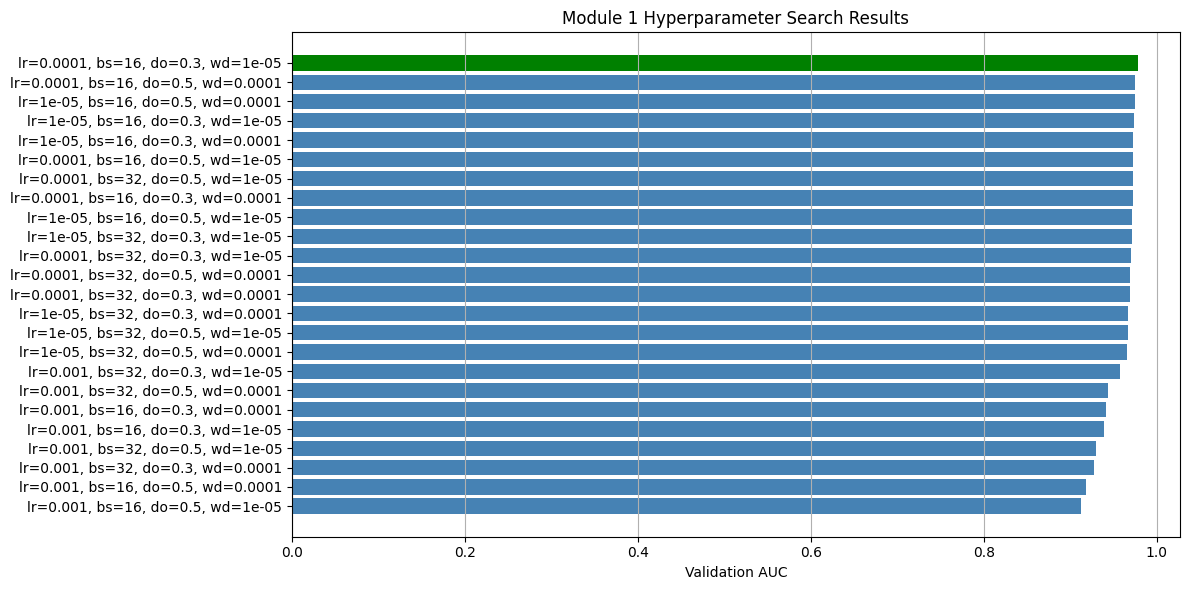

Search results saved


In [12]:
# Select and visualise the best hyperparameter configuration

# Convert search results to a DataFrame
results_df = pd.DataFrame(search_results)

# Rank configurations by validation AUC
results_df = (
    results_df
    .sort_values('val_auc', ascending=False)
    .reset_index(drop=True)
)

best_config = results_df.iloc[0].to_dict()
best_config['batch_size'] = int(best_config['batch_size'])

# Display ranked results
print("Hyperparameter search results (sorted by validation AUC)")
print(results_df.to_string(index=False))

print("\nBest configuration")
print(f"Learning rate: {best_config['lr']}")
print(f"Batch size: {best_config['batch_size']}")
print(f"Dropout: {best_config['dropout']}")
print(f"Weight decay: {best_config['weight_decay']}")
print(f"Validation AUC: {best_config['val_auc']:.4f}")

# Save results for future reference
results_df.to_csv(
    SEARCH_RESULTS_FILE,
    index=False
)

# Visualise validation AUC for all configurations
fig, ax = plt.subplots(figsize=(12, 6))

sorted_df = results_df.sort_values('val_auc')

plot_labels = [
    (
        f"lr={row['lr']}, "
        f"bs={int(row['batch_size'])}, "
        f"do={row['dropout']}, "
        f"wd={row['weight_decay']}"
    )
    for _, row in sorted_df.iterrows()
]

bar_colours = ['steelblue'] * len(sorted_df)
bar_colours[-1] = 'green'

ax.barh(
    plot_labels,
    sorted_df['val_auc'],
    color=bar_colours
)

ax.set_xlabel('Validation AUC')
ax.set_title('Module 1 Hyperparameter Search Results')
ax.grid(True, axis='x')

plt.tight_layout()

plt.savefig(
    f'{PROJECT}/outputs/m1_hyperparameter_search.png',
    dpi=150
)

plt.show()

print("Search results saved")

## **Build final model**

In [14]:
# Build the final model using the best hyperparameters

# Create the model using the selected configuration
model = build_resnet50(
    dropout=best_config['dropout']
)

# Define optimiser, learning rate scheduler, and loss function
optimizer = Adam(
    model.parameters(),
    lr=best_config['lr'],
    weight_decay=best_config['weight_decay']
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode='min',
    patience=3,
    factor=0.5
)

criterion = nn.CrossEntropyLoss(
    weight=weights_tensor
)

# Create data loaders
batch_size = best_config['batch_size']

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    sampler=sampler,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Calculate model size
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Display configuration summary
print("Final model configuration")
print(f"Learning rate: {best_config['lr']}")
print(f"Batch size: {batch_size}")
print(f"Dropout: {best_config['dropout']}")
print(f"Weight decay: {best_config['weight_decay']}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Final model configuration
Learning rate: 0.0001
Batch size: 16
Dropout: 0.3
Weight decay: 1e-05
Total parameters: 24,689,986
Trainable parameters: 24,689,986


## **Checkpoint functions**

In [15]:
# Define checkpoint save and load functions

def save_checkpoint(
    model,
    optimizer,
    scheduler,
    epoch,
    train_loss,
    val_loss,
    val_acc
):
    """
    Save the current training state to a checkpoint file.

    Args:
        model (torch.nn.Module): Model being trained.
        optimizer (torch.optim.Optimizer): Optimiser state.
        scheduler: Learning rate scheduler state.
        epoch (int): Current training epoch.
        train_loss (float): Training loss for the epoch.
        val_loss (float): Validation loss for the epoch.
        val_acc (float): Validation accuracy for the epoch.
    """
    torch.save(
        {
            'epoch': epoch,
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'scheduler_state': scheduler.state_dict(),
            'train_loss': train_loss,
            'val_loss': val_loss,
            'val_acc': val_acc,
            'best_config': best_config
        },
        CHECKPOINT
    )

    with open(TRAINING_LOG, 'a') as file:
        file.write(
            f"Epoch {epoch + 1:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%\n"
        )

    print(f"Checkpoint saved (Epoch {epoch + 1})")


def load_checkpoint(model, optimizer, scheduler):
    """
    Load a previously saved checkpoint if available.

    Args:
        model (torch.nn.Module): Model to restore.
        optimizer (torch.optim.Optimizer): Optimiser to restore.
        scheduler: Learning rate scheduler to restore.

    Returns:
        tuple: Restored model, optimiser, scheduler, and start epoch.
    """
    if os.path.exists(CHECKPOINT):

        checkpoint = torch.load(
            CHECKPOINT,
            map_location=device
        )

        model.load_state_dict(
            checkpoint['model_state']
        )

        optimizer.load_state_dict(
            checkpoint['optimizer_state']
        )

        scheduler.load_state_dict(
            checkpoint['scheduler_state']
        )

        start_epoch = checkpoint['epoch'] + 1

        print(
            f"Training resumed from epoch "
            f"{checkpoint['epoch'] + 1} | "
            f"Validation accuracy: "
            f"{checkpoint['val_acc']:.2f}%"
        )

        return (model, optimizer, scheduler, start_epoch)

    print("No checkpoint found. Starting training from scratch.")

    return (model, optimizer, scheduler, 0)

print("Checkpoint functions defined")

Checkpoint functions defined


## **Training Loop**

In [16]:
# Main training loop for ResNet-50 model

# Load checkpoint if available
model, optimizer, scheduler, start_epoch = load_checkpoint(
    model,
    optimizer,
    scheduler
)

# Training configuration
NUM_EPOCHS = 20
PATIENCE = 5
best_val_acc = 0.0
best_val_loss = float('inf')
patience_counter = 0
history = {'train_loss': [],
           'val_loss': [],
           'train_acc': [],
           'val_acc': []}

print(
    f"Training started | Max epochs: {NUM_EPOCHS} | "
    f"Early stopping patience: {PATIENCE}"
)

# Training loop
for epoch in range(start_epoch, NUM_EPOCHS):

    # Training phase
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS} [Train]"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        train_correct += predictions.eq(labels).sum().item()
        train_total += labels.size(0)

    avg_train_loss = train_loss / len(train_loader)
    train_accuracy = 100.0 * train_correct / train_total

    # Validation phase
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    all_predictions = []
    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1}/{NUM_EPOCHS} [Val]"
        ):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)
            val_loss += loss.item()

            probabilities = torch.softmax(outputs, dim=1)[:, 1]
            predictions = outputs.argmax(dim=1)

            val_correct += predictions.eq(labels).sum().item()
            val_total += labels.size(0)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = 100.0 * val_correct / val_total

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average='weighted'
    )

    val_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    # Update learning rate scheduler
    scheduler.step(avg_val_loss)

    # Save metrics history
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['train_acc'].append(train_accuracy)
    history['val_acc'].append(val_accuracy)

    # Print epoch summary
    print(f"\nEpoch [{epoch + 1}/{NUM_EPOCHS}]")
    print(
        f"Train - Loss: {avg_train_loss:.4f} | "
        f"Accuracy: {train_accuracy:.2f}%"
    )
    print(
        f"Val   - Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.2f}% | "
        f"F1: {val_f1:.4f} | AUC: {val_auc:.4f}"
    )

    # Save checkpoint
    save_checkpoint(
        model,
        optimizer,
        scheduler,
        epoch,
        avg_train_loss,
        avg_val_loss,
        val_accuracy
    )

    # Track best model
    if val_accuracy > best_val_acc:

        best_val_acc = val_accuracy
        best_val_loss = avg_val_loss
        patience_counter = 0

        torch.save(model.state_dict(), BEST_MODEL)

        print(f"Best model updated (Val Acc: {val_accuracy:.2f}%)")

    else:
        patience_counter += 1
        print(
            f"No improvement "
            f"({patience_counter}/{PATIENCE})"
        )

    # Early stopping
    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch + 1}")
        break

print(f"\nTraining complete | Best Val Accuracy: {best_val_acc:.2f}%")

No checkpoint found. Starting training from scratch.
Training started | Max epochs: 20 | Early stopping patience: 5


Epoch 1/20 [Val]: 100%|██████████| 39/39 [00:04<00:00,  8.41it/s]



Epoch [1/20]
Train - Loss: 0.2734 | Accuracy: 88.85%
Val   - Loss: 0.1987 | Accuracy: 91.92% | F1: 0.9191 | AUC: 0.9681
Checkpoint saved (Epoch 1)
Best model updated (Val Acc: 91.92%)


Epoch 2/20 [Val]: 100%|██████████| 39/39 [00:04<00:00,  8.45it/s]



Epoch [2/20]
Train - Loss: 0.1757 | Accuracy: 93.84%
Val   - Loss: 0.2260 | Accuracy: 90.31% | F1: 0.9031 | AUC: 0.9678
Checkpoint saved (Epoch 2)
No improvement (1/5)


Epoch 3/20 [Val]: 100%|██████████| 39/39 [00:04<00:00,  8.94it/s]


... (7 outputs left out)

Epoch 7/20 [Val]: 100%|██████████| 39/39 [00:04<00:00,  8.49it/s]



Epoch [7/20]
Train - Loss: 0.0775 | Accuracy: 97.06%
Val   - Loss: 0.2287 | Accuracy: 91.44% | F1: 0.9144 | AUC: 0.9719
Checkpoint saved (Epoch 7)
No improvement (4/5)


Epoch 8/20 [Val]: 100%|██████████| 39/39 [00:04<00:00,  8.81it/s]



Epoch [8/20]
Train - Loss: 0.0508 | Accuracy: 98.37%
Val   - Loss: 0.2538 | Accuracy: 91.60% | F1: 0.9160 | AUC: 0.9718
Checkpoint saved (Epoch 8)
No improvement (5/5)

Early stopping triggered at epoch 8

Training complete | Best Val Accuracy: 93.21%


## **Evaluate and plot**

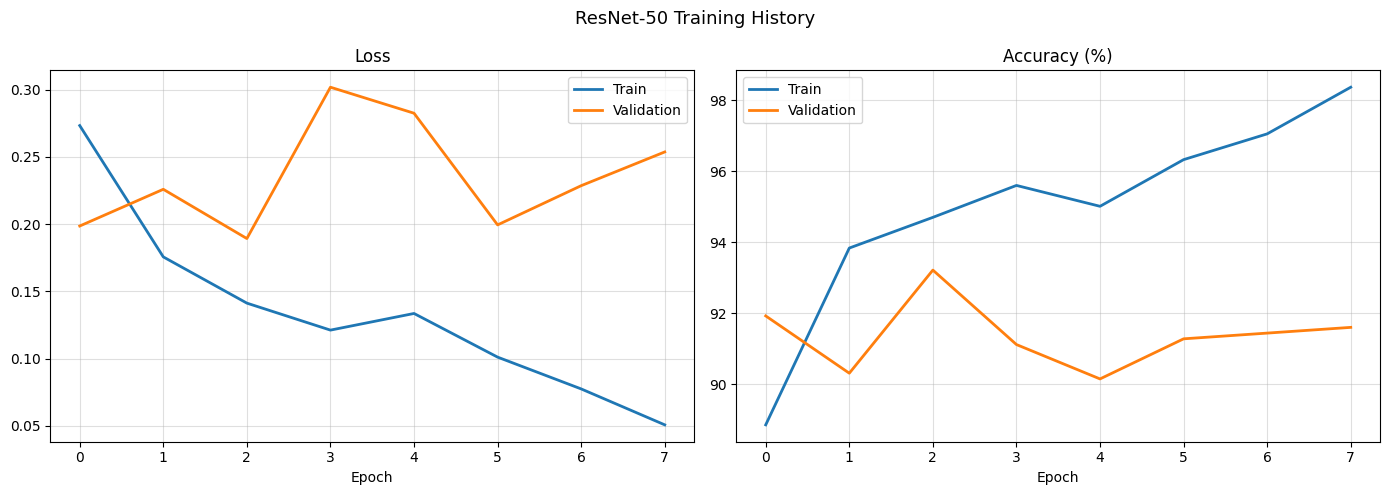

Test evaluation: 100%|██████████| 39/39 [00:04<00:00,  8.76it/s]



Module 1 Test Results
              precision    recall  f1-score   support

        Real       0.93      0.85      0.89       322
        Fake       0.85      0.93      0.89       298

    accuracy                           0.89       620
   macro avg       0.89      0.89      0.89       620
weighted avg       0.89      0.89      0.89       620

AUC-ROC: 0.9481


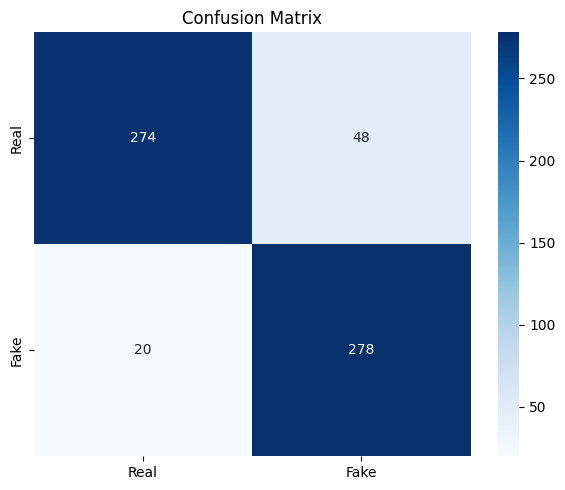

In [17]:
# Evaluate model on test set and visualise training curves


# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ResNet-50 Training History', fontsize=13)

# Loss curve
axes[0].plot(history['train_loss'], label='Train', lw=2)
axes[0].plot(history['val_loss'], label='Validation', lw=2)
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.4)

# Accuracy curve
axes[1].plot(history['train_acc'], label='Train', lw=2)
axes[1].plot(history['val_acc'], label='Validation', lw=2)
axes[1].set_title('Accuracy (%)')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(
    f'{PROJECT}/outputs/m1_training_curves.png',
    dpi=150
)
plt.show()


# Test evaluation
model.load_state_dict(
    torch.load(BEST_MODEL, map_location=device)
)

model.eval()

test_predictions = []
test_labels = []
test_probabilities = []

with torch.no_grad():

    for images, labels in tqdm(test_loader, desc="Test evaluation"):

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)[:, 1]
        predictions = outputs.argmax(dim=1)

        test_predictions.extend(predictions.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())
        test_probabilities.extend(probabilities.cpu().numpy())


# Metrics
print("\nModule 1 Test Results")

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=['Real', 'Fake']
    )
)

test_auc = roc_auc_score(
    test_labels,
    test_probabilities
)

print(f"AUC-ROC: {test_auc:.4f}")


# Confusion matrix
conf_matrix = confusion_matrix(test_labels, test_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Real', 'Fake'],
    yticklabels=['Real', 'Fake']
)

plt.title('Confusion Matrix')
plt.tight_layout()

plt.savefig(
    f'{PROJECT}/outputs/m1_confusion_matrix.png',
    dpi=150
)

plt.show()

## **Save predictions for fusion**

In [18]:
# Save Module 1 predictions for fusion classifier

# Save test predictions, probabilities, and ground-truth labels
np.save(
    f'{PREDICTIONS_DIR}/m1_test_probs.npy',
    np.array(test_probabilities)
)

np.save(
    f'{PREDICTIONS_DIR}/m1_test_preds.npy',
    np.array(test_predictions)
)

np.save(
    f'{PREDICTIONS_DIR}/m1_test_labels.npy',
    np.array(test_labels)
)

print("...Module 1 predictions saved...")
print(f"Test probabilities: {len(test_probabilities)}")
print(f"Test predictions: {len(test_predictions)}")
print(f"Test labels: {len(test_labels)}")
print(f"Saved to: {PREDICTIONS_DIR}")
print("Ready for fusion classifier (Module 5)")

...Module 1 predictions saved...
Test probabilities: 620
Test predictions: 620
Test labels: 620
Saved to: /content/drive/MyDrive/fake_image_detection/predictions
Ready for fusion classifier (Module 5)


## **Grad-CAM**

In [19]:
# Generate Grad-CAM visualisations for model interpretability

# Grad-CAM setup
target_layers = [model.layer4[-1]]

cam = GradCAM(
    model=model,
    target_layers=target_layers
)

# Preprocessing for visualisation
eval_transform_plain = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Select random real and fake samples
real_samples = random.sample(
    [s for s in full_dataset.samples if s[1] == 0], 4
)

fake_samples = random.sample(
    [s for s in full_dataset.samples if s[1] == 1], 4
)

samples = real_samples + fake_samples

# Visualise original images and Grad-CAM heatmaps
fig, axes = plt.subplots(2, 8, figsize=(20, 6))

fig.suptitle(
    "Grad-CAM Visualisation (ResNet-50)\n"
    "Top: Original Images | Bottom: Attention Maps",
    fontsize=11
)

for index, (image_path, label) in enumerate(samples):

    image_pil = Image.open(image_path).convert('RGB').resize((224, 224))
    image_np = np.array(image_pil) / 255.0

    image_tensor = (
        eval_transform_plain(image_pil)
        .unsqueeze(0)
        .to(device)
    )

    grayscale_cam = cam(
        input_tensor=image_tensor,
        targets=[ClassifierOutputTarget(label)]
    )

    cam_image = show_cam_on_image(
        image_np.astype(np.float32),
        grayscale_cam[0],
        use_rgb=True
    )

    # Original image
    axes[0][index].imshow(image_pil)
    axes[0][index].set_title(
        "Real" if label == 0 else "Fake",
        fontsize=9
    )
    axes[0][index].axis('off')

    # Grad-CAM heatmap
    axes[1][index].imshow(cam_image)
    axes[1][index].set_title("Grad-CAM", fontsize=9)
    axes[1][index].axis('off')

plt.tight_layout()

plt.savefig(
    f'{PROJECT}/outputs/m1_gradcam.png',
    dpi=150
)

plt.show()

print("Grad-CAM visualisation saved")

Grad-CAM visualisation saved
